# Figures for *A spectral theory for turbulent burning velocity across scales* (JFM Rapids)

Reads the datasets in `data/` (described in `README.md`) and writes, to `figures/`,
one PDF (and a 1200 dpi PNG preview) per panel, the table symbols `sym_*.pdf`, and `predictions.csv`.
Figures for the supplementary material are written as `supp_*.pdf`.

**Model** (manuscript §3):

$$\frac{s_T}{s_L} = \left[1 + \mathcal{C}\,\mathcal{F}(Re)\,\frac{u'}{s_L}\right]^{1/2},\qquad
\mathcal{F}(Re) = \int_1^{Re^{3/4}} \kappa^{*-4/3}\left(1+\frac{c_L}{\kappa^{*2}}\right)^{-(5/3+p_0)/4}
\exp\!\left(-\frac{\beta\kappa^*}{2Re^{3/4}}\right)\mathrm{d}\kappa^*,\qquad
\mathcal{C} = D_e^+ C^{1/2}(3/2)^{1/3},$$

with $\kappa^* = \kappa\ell_0$ and $D_e^+ = \nu_e^+/Sc_T$. This is identical to the $\hat\kappa$ form
$C''Ka^{2/3}\int\hat\kappa^{-4/3}\hat f_L^{1/2}\hat f_\eta^{1/2}\,\mathrm{d}\hat\kappa$ of the paper
(substitute $\hat\kappa = Ka^{1/2}Re^{-3/4}\kappa^*$ and use $Ka^{1/2}Re^{1/4} = u'/s_L$).

**Data choices**:
* the Michigan-2005 $A_T/A$ carries a consistency factor $2/\pi$ for comparing its slot burner with the round burners (`AREA_CORR`);
* methane–air at 0.1 MPa only, apart from the propane–butane–oxygen flames of Damköhler (1940);
* a single isosurface, $\bar c = 0.5$, wherever the source reports it.

$Re$ and $Ka$ are computed from the tabulated $u'/s_L$ and $\ell_0/\delta_L$.

## Setup: paths and spectral constants

In [1]:
import os
import re
import unicodedata
import numpy as np
import pandas as pd
import matplotlib
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D
from matplotlib.legend_handler import HandlerTuple
from scipy.integrate import quad, trapezoid
from scipy.optimize import curve_fit

HERE = os.getcwd()                     # run from the repository folder
DATA = os.path.join(HERE, 'data')
OUT = os.path.join(HERE, 'figures')
os.makedirs(OUT, exist_ok=True)

C = 1.5            # Kolmogorov constant
BETA = 5.2         # dissipation-range constant (Pope 2000)
C_L = 6.78         # energy-containing-range constant (Pope 2000)
P0 = 0.0           # low-wavenumber exponent of f_L
NU_E = 0.8676      # spectral eddy viscosity at the cusp, nu_e^+(1), fit to Chollet (1984)
SC_T = 0.4616      # spectral turbulent Schmidt number at the cusp, nu_e^+/D_e^+
D_E = NU_E / SC_T
CS = D_E * C**0.5 * 1.5**(1 / 3)
print(f'D_e+ = {D_E:.3f},  C = D_e+ C^1/2 (3/2)^1/3 = {CS:.3f}')

D_e+ = 1.880,  C = D_e+ C^1/2 (3/2)^1/3 = 2.635


## Data

In [2]:
RE_CORR = {}  # e.g. {'Toronto (2013)': 6.6}; default 1.0 = use (u'/s_L)(l0/dL) as tabulated
AREA_CORR = {'Michigan (2005)': 2 / np.pi}  # consistency factor for comparing the slot burner with round burners

# (label, file, s_T column, row filter, marker)
DATASETS = [
    ('Michigan (2017)', 'Wabel_2017_Michigan.csv', 'st/sl_c=0.5', None, '^'),
    ('Toronto (2013)', 'Yuen_2013_Toronto.csv', 'st/sl_c=0.5', lambda d: d['Fuel'] == 'CH4', 'o'),
    ('Tohoku (1996)', 'Kobayashi_1996_Tohoku.csv', 'st/sl_c=0.5',
     lambda d: pd.to_numeric(d['P (MPa)'], errors='coerce') == 0.1, 'v'),
    ('Aachen (2000)', 'Plessing_2000_Aachen.csv', 'st/sl_c=0.5', None, 's'),
    ('Ottawa (1995)', 'Smallwood_1995_Ottawa.csv', 'st/sl_c=0.05', None, 'D'),
    ('Toronto (2014)', 'Tamadonfar_2014_Toronto.csv', 'st/sl_c=0.5', None, '<'),
    ('Michigan (2005)', 'Filatyev_2005_Michigan.csv', 'st/sl_c=0.5', None, '>'),
]
AREA = {  # area-ratio column used for figures 1(b) and 3(b)
    'Michigan (2017)': 'At/Al_shepherd',
    'Toronto (2013)': 'At/Al_grad_c',
    'Michigan (2005)': '(P_T/P)^2',  # square of the measured flame-perimeter ratio
}


def _num(df, col):
    return pd.to_numeric(df[col], errors='coerce').to_numpy()


def load():
    sets = []
    for label, fname, stcol, filt, mk in DATASETS:
        d = pd.read_csv(os.path.join(DATA, fname))
        if filt is not None:
            d = d[filt(d).fillna(False)]
        usl, ldl, st = _num(d, "u'/sl"), _num(d, 'l0/dl'), _num(d, stcol)
        at = _num(d, AREA[label]) * AREA_CORR.get(label, 1.0) if label in AREA else np.full_like(usl, np.nan)
        m = np.isfinite(usl) & np.isfinite(ldl) & np.isfinite(st)
        sets.append(dict(label=label, marker=mk, usl=usl[m], ldl=ldl[m], st=st[m], at=at[m],
                         re=usl[m] * ldl[m] * RE_CORR.get(label, 1.0)))
    dk = pd.read_csv(os.path.join(DATA, 'Damkohler_1940.csv'), float_precision='round_trip')
    usl, ldl = dk["u'/sl"].to_numpy(float), dk['l0/dl'].to_numpy(float)
    st = dk['wf_max/wf_min'].to_numpy(float)
    m = np.isfinite(usl) & np.isfinite(ldl) & np.isfinite(st)
    sets.append(dict(label='Damköhler (1940)', marker='p', usl=usl[m], ldl=ldl[m], st=st[m],
                     at=np.full(m.sum(), np.nan), re=usl[m] * ldl[m]))
    for s in sets:
        with np.errstate(divide='ignore'):
            s['ka'] = s['usl']**1.5 * s['ldl']**-0.5
    return sets


sets = load()
for s in sets:
    print(f"{s['label']:18s} n = {len(s['st'])}")

Michigan (2017)    n = 18
Toronto (2013)     n = 8
Tohoku (1996)      n = 4
Aachen (2000)      n = 6
Ottawa (1995)      n = 6
Toronto (2014)     n = 16
Michigan (2005)    n = 7
Damköhler (1940)   n = 15


## Model: $\mathcal{F}(Re)$ and $s_T/s_L$

In [3]:
def F_exact(Re, p0=P0, beta=BETA, cL=C_L):
    if Re <= 1.0:
        return 0.0
    g = (5 / 3 + p0) / 4
    f = lambda k: k**(-4 / 3) * (1 + cL / k**2)**(-g) * np.exp(-beta * k * Re**-0.75 / 2)
    return quad(f, 1.0, Re**0.75, epsrel=1e-9, limit=500)[0]


def F_inf(p0=P0, cL=C_L):
    return quad(lambda k: k**(-4 / 3) * (1 + cL / k**2)**(-(5 / 3 + p0) / 4), 1, np.inf)[0]


_lre = np.linspace(0, 7, 701)          # tabulate F on log10(Re) for fast interpolation
_F = np.array([F_exact(10**x) for x in _lre])


def F(Re):
    Re = np.asarray(Re, float)
    return np.interp(np.log10(np.clip(Re, 1, None)), _lre, _F)


def sT(usl, Re):
    return np.sqrt(1 + CS * np.asarray(usl) * F(Re))


for p0 in (0, 2, 4):
    print(f'p0={p0}: F(1e3)={F_exact(1e3, p0):.3f}  F(1e6)={F_exact(1e6, p0):.3f}  F_inf={F_inf(p0):.3f}')

p0=0: F(1e3)=1.596  F(1e6)=2.380  F_inf=2.557
p0=2: F(1e3)=1.291  F(1e6)=2.062  F_inf=2.239
p0=4: F(1e3)=1.105  F(1e6)=1.868  F_inf=2.045


## Style and helpers

In [4]:
plt.style.use('classic')
matplotlib.rcParams['savefig.bbox'] = 'tight'
INK, AREA_C = 'k', 'b'
MS, MEW = 10, 1.8                      # marker size and edge width
LABEL, TICK, LEGEND, NOTE = 22, 14, 14, 16
PANEL = (7, 5)                         # inches, one panel per file


def contrast_coolwarm(n=256, mid=0.92, dark=0.37):
    # coolwarm with darker ends: RGB scaled by `mid` at the centre, falling to `mid - dark` at both ends
    rgba = plt.get_cmap('coolwarm')(np.linspace(0, 1, n))
    d = np.abs(np.linspace(-1, 1, n))
    rgba[:, :3] *= (mid - dark * d**1.3)[:, None]
    return matplotlib.colors.ListedColormap(rgba, name='coolwarm_dark')


CMAP = contrast_coolwarm()


def mark(ax, x, y, s, c=INK, **kw):
    ax.plot(x, y, ls='none', marker=s['marker'], mfc='none', mec=c, mew=MEW, ms=MS, **kw)


def area_bars(ax, x, s):
    ax.errorbar(x, s['at'], yerr=0.2 * s['at'], ls='none', marker=s['marker'], mfc='none', mec=AREA_C,
                ms=MS, mew=MEW, ecolor=AREA_C, elinewidth=1.3)


def panel():
    fig, ax = plt.subplots(figsize=PANEL)
    ax.tick_params(axis='both', which='major', labelsize=TICK)
    return fig, ax


def save(fig, name):
    for ext, kw in (('.pdf', {}), ('.png', {'dpi': 1200})):
        path = os.path.join(OUT, name + ext)
        if os.path.exists(path):
            os.remove(path)  # on Windows an open viewer can block overwriting in place
        fig.savefig(path, **kw)
    plt.show()


def pair_handles(labels):
    # legend entries showing the s_T (black) and A_T/A (blue) marker of each dataset
    return [(Line2D([], [], ls='none', marker=s['marker'], mfc='none', mec=INK, mew=MEW, ms=MS),
             Line2D([], [], ls='none', marker=s['marker'], mfc='none', mec=AREA_C, mew=MEW, ms=MS))
            for s in sets if s['label'] in labels]

## Figure 1(a): regime diagram

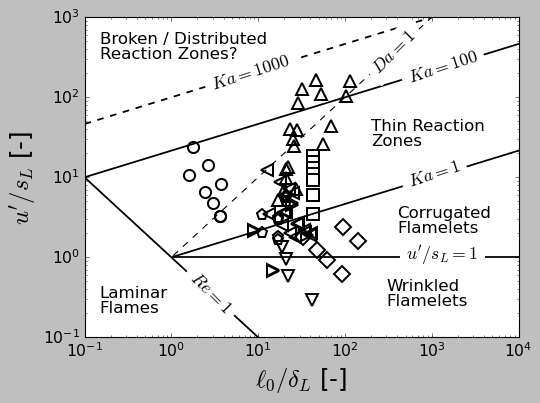

In [5]:
fig, a = panel()
x = np.logspace(-1, 4, 50)
a.loglog(x[x < 100], 1 / x[x < 100], 'k', lw=1.6)                 # Re = 1
a.loglog(x[x >= 1], x[x >= 1]**(1 / 3), 'k', lw=1.6)              # Ka = 1
a.loglog(x[x >= 1], x[x >= 1]**(1), 'k--', lw=1)              # Da = 1
a.loglog(x, 100**(2 / 3) * x**(1 / 3), 'k', lw=1.6)               # Ka = 100
a.loglog(x, 1000**(2 / 3) * x**(1 / 3), 'k--', lw=1.6)              # Ka = 1000
a.loglog(x[x >= 1], np.ones((x >= 1).sum()), 'k', lw=1.6)         # u'/s_L = 1
a.text(500, 7.5, r'$\mathit{Ka} = 1$', backgroundcolor='white', rotation=18, fontsize=NOTE)
a.text(500, 150, r'$\mathit{Ka} = 100$', backgroundcolor='white', rotation=18, fontsize=NOTE)
a.text(2.7, 125, r'$\mathit{Ka} = 1000$', backgroundcolor='white', rotation=18, fontsize=NOTE)
a.text(1.5, 0.2, r'$\mathit{Re} = 1$', backgroundcolor='white', rotation=-45, fontsize=NOTE)
a.text(190, 200, r'$\mathit{Da} = 1$', backgroundcolor='white', rotation=45, fontsize=NOTE)
a.text(500, 0.92, r"$u^\prime/s_L = 1$", backgroundcolor='white', fontsize=NOTE)
reg = dict(fontsize=15, color='k', linespacing=1.0)
a.text(400, 2.0, 'Corrugated\nFlamelets', **reg)
a.text(200, 25, 'Thin Reaction\nZones', **reg)
a.text(0.15, 300, 'Broken / Distributed\nReaction Zones?', **reg)
a.text(300, 0.25, 'Wrinkled\nFlamelets', **reg)
a.text(0.15, 0.2, 'Laminar\nFlames', **reg)
for s in sets:
    mark(a, s['ldl'], s['usl'], s)
a.set_xlim(0.1, 1e4); a.set_ylim(0.1, 1e3)
a.set_xlabel(r'$\ell_0/\delta_L$ [-]', fontsize=LABEL)
a.set_ylabel(r"$u^\prime/s_L$ [-]", fontsize=LABEL)
save(fig, 'fig1a_regime')

## Figure 1(b): $s_T/s_L$ and $A_T/A$ against $Ka$

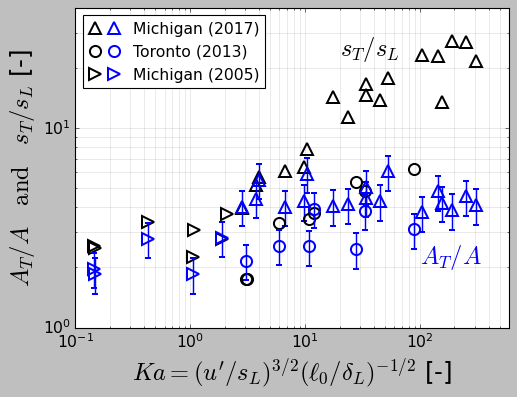

In [6]:
fig, b = panel()
for s in sets:
    if s['label'] in AREA:
        mark(b, s['ka'], s['st'], s)
        area_bars(b, s['ka'], s)
b.set_xscale('log'); b.set_yscale('log')
b.text(20, 23, r'$s_T/s_L$', color=INK, fontsize=22)
b.text(100, 2.1, r'$A_T/A$', color=AREA_C, fontsize=22)
b.set_xlim(0.1, 600); b.set_ylim(1, 40)
b.set_xlabel(r'$\mathit{Ka} = (u^\prime/s_L)^{3/2}(\ell_0/\delta_L)^{-1/2}$ [-]', fontsize=LABEL)
b.set_ylabel(r'$A_T/A \quad \mathrm{and} \quad s_T/s_L$ [-]', fontsize=LABEL)
labels = [s['label'] for s in sets if s['label'] in AREA]
b.legend(pair_handles(labels), labels, handler_map={tuple: HandlerTuple(ndivide=None)},
         loc='upper left', fontsize=LEGEND, numpoints=1)
b.grid(which='both', color='k', linestyle='-', linewidth=0.5, alpha=0.15)
save(fig, 'fig1b_area')

## Figure 2(a): model spectrum in flame units

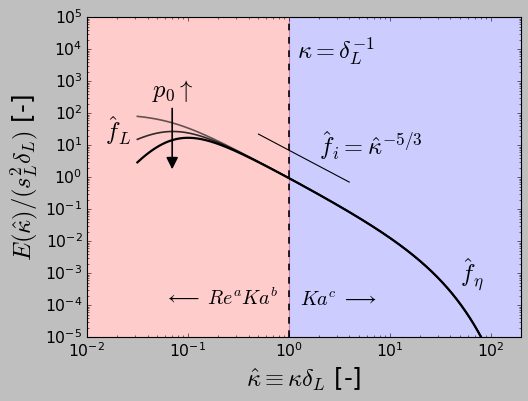

In [7]:
fig, a = panel()
a.set_xscale('log'); a.set_yscale('log')
a.set_xlim(0.01, 200); a.set_ylim(1e-5, 1e5)    # fixed first: f_eta underflows to 0 at large k
k = np.logspace(-1.5, 6, 10000)        # kappa_hat = kappa * delta_L
L0, ETA = 40, 0.01                      # illustrative l0/delta_L and eta/delta_L
f_i = k**(-5 / 3)
f_eta = np.exp(-BETA * k * ETA)
for p0, lw, alpha in [(0, 1.5, 0.6), (2, 1.5, 0.8), (4, 2.0, 1.0)]:
    f_L = (1 + C_L * (k * L0)**-2)**(-(5 / 3 + p0) / 2)
    a.loglog(k, f_i * f_eta * f_L, 'k-', lw=lw, alpha=alpha)
a.loglog(k[1600:2800], 7 * f_i[1600:2800], 'k-', lw=1)           # kappa_hat^-5/3 guide
a.annotate(r'$p_0 \uparrow$', xy=(0.07, 1.5), xytext=(0.07, 200), fontsize=LABEL, ha='center', va='bottom',
           arrowprops=dict(arrowstyle='-|>', color='k', lw=1.5))
a.text(50, 5e-4, r'$\hat{f}_\eta$', fontsize=LABEL)
a.text(0.015, 15, r'$\hat{f}_L$', fontsize=LABEL)
a.text(2, 5, r'$\hat{f}_i = \hat{\kappa}^{-5/3}$', fontsize=LABEL)
a.text(1.2, 5000, r'$\kappa = \delta_L^{-1}$', fontsize=LABEL)
a.text(1.3, 1e-4, r'$\mathit{Ka}^c \; \longrightarrow$', fontsize=18, ha='left')
a.text(0.8, 1e-4, r'$\longleftarrow \; \mathit{Re}^a \mathit{Ka}^b$', fontsize=18, ha='right')
a.axvspan(1, 1000, alpha=0.2, color='blue')
a.axvspan(0.001, 1, alpha=0.2, color='red')
a.axvline(1, ls='--', lw=1.5, color='k')
a.set_xlabel(r'$\hat{\kappa} \equiv \kappa \delta_L$ [-]', fontsize=LABEL)
a.set_ylabel(r'$E(\hat{\kappa})/(s_L^2 \delta_L)$ [-]', fontsize=LABEL)
save(fig, 'fig2a_spectrum')

## Figure 2(b): spectral eddy viscosity and diffusivity of Chollet (1984), with fits
Fits of the Pope (2000) form $\nu_e^+ = C^{-3/2}[A + B\exp(-c\,\kappa_c/\kappa)]$ to Chollet's $\nu_e^+$ and $D_e^+$; $Sc_T = \nu_e^+/D_e^+$. The cusp values set `NU_E` and `SC_T` above.

In [8]:
chollet = pd.read_csv(os.path.join(DATA, 'Chollet_1984_spectral_eddy_viscosity.csv'), float_precision='round_trip')


def chollet_curve(q):
    c = chollet[chollet['quantity'] == q].iloc[:-1]                # last digitised point not used in the fits
    return c['k/kc'].to_numpy(), c['value'].to_numpy()


k_D, D_ch = chollet_curve('D_e+')
k_nu, nu_ch = chollet_curve('nu_e+')
k_Sc, Sc_ch = chollet_curve('Sc_T')


def pope_form(x, A, B, c):
    return C**-1.5 * (A + B * np.exp(-c / x))


POPE_NU = (0.441, 15.2, 3.03)                                      # Pope (2000) regression for nu_e^+
popt_nu, _ = curve_fit(pope_form, k_nu, nu_ch)
popt_D, _ = curve_fit(pope_form, k_D, D_ch)
nu1, D1 = pope_form(1.0, *popt_nu), pope_form(1.0, *popt_D)
print(f'Pope (2000), nu_e+:  A = {POPE_NU[0]:.6f}, B = {POPE_NU[1]:.6f}, c = {POPE_NU[2]:.6f};  '
      f'nu_e+(1) = {pope_form(1.0, *POPE_NU):.4f}')
print(f'this work,   nu_e+:  A = {popt_nu[0]:.6f}, B = {popt_nu[1]:.6f}, c = {popt_nu[2]:.6f};  nu_e+(1) = {nu1:.4f}')
print(f'this work,   D_e+:   A = {popt_D[0]:.6f}, B = {popt_D[1]:.6f}, c = {popt_D[2]:.6f};  D_e+(1) = {D1:.4f}')
print(f'this work,   Sc_T(1) = nu_e+(1)/D_e+(1) = {nu1 / D1:.4f}')
assert abs(nu1 - NU_E) < 5e-4 and abs(nu1 / D1 - SC_T) < 5e-4, 'fits no longer match NU_E, SC_T'

Pope (2000), nu_e+:  A = 0.441000, B = 15.200000, c = 3.030000;  nu_e+(1) = 0.6398
this work,   nu_e+:  A = 0.492697, B = 162.712902, c = 4.995631;  nu_e+(1) = 0.8676
this work,   D_e+:   A = 0.871697, B = 949.459569, c = 5.907623;  D_e+(1) = 1.8795
this work,   Sc_T(1) = nu_e+(1)/D_e+(1) = 0.4616


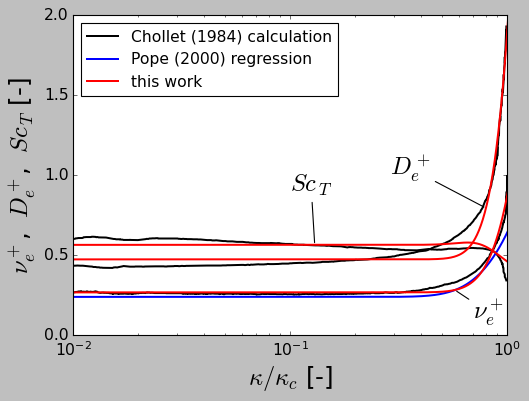

In [9]:
fig, ax = panel()
ax.set_xscale('log')
ax.plot(k_D, D_ch, 'k', lw=1.8, label='Chollet (1984) calculation')
ax.plot(k_nu, nu_ch, 'k', lw=1.8)
ax.plot(k_Sc, Sc_ch, 'k', lw=1.8)
kk = np.logspace(-2, 1, 1000)
ax.plot(kk, pope_form(kk, *POPE_NU), 'b', lw=1.8, label='Pope (2000) regression')
nu_fit, D_fit = pope_form(kk, *popt_nu), pope_form(kk, *popt_D)
ax.plot(kk, D_fit, 'r', lw=1.8, label='this work')
ax.plot(kk, nu_fit, 'r', lw=1.8)
ax.plot(kk, nu_fit / D_fit, 'r', lw=1.8)
lead = dict(arrowstyle='-', color='k', lw=1)                       # leader lines from label to curve
ax.annotate(r'$\nu_e^+$', xy=(0.575, pope_form(0.575, *popt_nu)), xytext=(0.7, 0.1), fontsize=LABEL,
            arrowprops=lead)
ax.annotate(r'$D_e^+$', xy=(0.8, pope_form(0.8, *popt_D)), xytext=(0.29, 1.0), fontsize=LABEL, arrowprops=lead)
ax.annotate(r'$\mathit{Sc}_{\, T}$', xy=(0.13, pope_form(0.13, *popt_nu) / pope_form(0.13, *popt_D)),
            xytext=(0.1, 0.9), fontsize=LABEL, arrowprops=lead)
ax.set_xlim(0.01, 1); ax.set_ylim(0, 2)
ax.set_xlabel(r'$\kappa/\kappa_c$ [-]', fontsize=LABEL)
ax.set_ylabel(r'$\nu_e^+$, $\; D_e^+$, $\; \mathit{Sc}_{\, T}$ [-]', fontsize=LABEL)
ax.legend(loc='upper left', fontsize=LEGEND, numpoints=1)
save(fig, 'fig2b_chollet')

## Figure 3(a): the spectral function $\mathcal{F}(Re)$

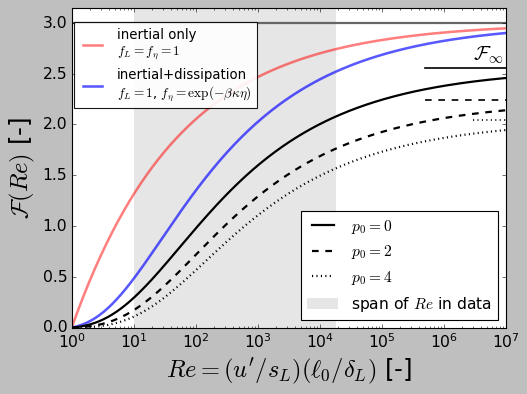

In [10]:
fig, a = panel()
Re = np.logspace(0, 7, 300)
data_re = np.concatenate([s['re'][s['re'] > 0] for s in sets])
a.axvspan(data_re.min(), data_re.max(), color='0.9', lw=0, zorder=0,     # range of the data
          label=r'span of $\mathit{Re}$ in data')
a.axhline(3, color='0.4', lw=2)
a.semilogx(Re, 3 * (1 - Re**-0.25), color='red', alpha=0.5, lw=2.3, label='inertial only\n' + r'$f_L = f_\eta = 1$')
a.semilogx(Re, [F_exact(r, cL=0.0) for r in Re], color='blue', alpha=0.65, ls='-', lw=2.3,
           label='inertial+dissipation\n' + r'$f_L = 1$, $f_\eta = \exp(-\beta \kappa \eta)$')
for p0, ls in [(0, '-'), (2, '--'), (4, ':')]:
    a.semilogx(Re, [F_exact(r, p0) for r in Re], 'k', ls=ls, lw=2, label=rf'$p_0 = {p0}$')
    a.plot([3e6 if p0 == 4 else 5e5, 1e7], [F_inf(p0)] * 2, 'k', ls=ls, lw=1.5)  # F_inf; p0 = 4 shorter
a.set_xlim(1, 1e7); a.set_ylim(0, 3.15)
a.text(3 * 10**6, 2.63, r'$\mathcal{F}_\infty$', color=INK, fontsize=18)
a.set_xlabel(r'$\mathit{Re}= (u^\prime/s_L)(\ell_0/\delta_L)$ [-]', fontsize=LABEL)
a.set_ylabel(r'$\mathcal{F}(\mathit{Re})$ [-]', fontsize=LABEL)
h, l = a.get_legend_handles_labels()            # order: shading, inertial, inertial+dissipation, p0 = 0, 2, 4
a.add_artist(a.legend(h[1:3], l[1:3], loc='center left', bbox_to_anchor=(-0.01, 0.82), fontsize=12,
                      handlelength=2, framealpha=0.9))
a.legend(h[3:] + h[:1], l[3:] + l[:1], loc='lower right', fontsize=14, handlelength=2, framealpha=1)
save(fig, 'fig3a_F')

## Figure 3(b): measured against predicted

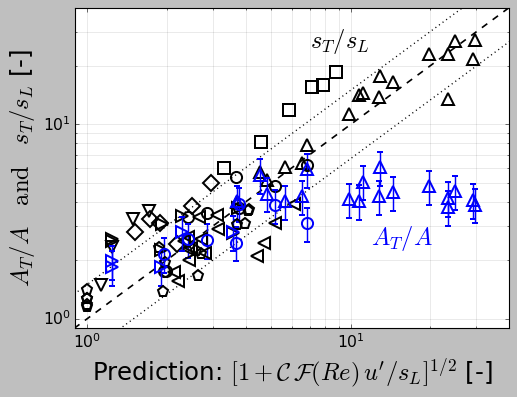

In [11]:
fig, ax = panel()
x = np.logspace(np.log10(0.4), np.log10(50), 100)
ax.loglog(x, x, 'k--', lw=1.5)
ax.loglog(x, 1.5 * x, 'k:', lw=1.2)
ax.loglog(x, x / 1.5, 'k:', lw=1.2)
for s in sets:
    p = sT(s['usl'], s['re'])
    mark(ax, p, s['st'], s)
    if s['label'] in AREA:
        area_bars(ax, p, s)
ax.text(7, 25, r'$s_T/s_L$', color=INK, fontsize=22)
ax.text(12, 2.4, r'$A_T/A$', color=AREA_C, fontsize=22)
ax.set_xlim(0.9, 40); ax.set_ylim(0.9, 40)
ax.set_xlabel(r"Prediction: $[1 + \mathcal{C}\,\mathcal{F}(\mathit{Re})\,u^\prime/s_L]^{1/2}$ [-]",
              fontsize=LABEL)
ax.set_ylabel(r'$A_T/A \quad \mathrm{and} \quad s_T/s_L$ [-]', fontsize=LABEL)
ax.grid(which='both', color='k', linestyle='-', linewidth=0.5, alpha=0.15)
save(fig, 'fig3b_comparison')

## Figure 4(a): bending of $s_T$ with $u'/s_L$

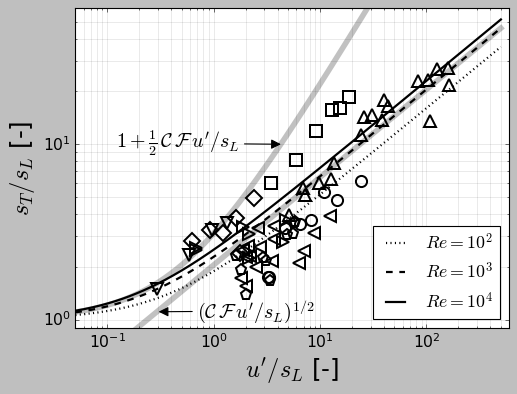

In [12]:
fig, a = panel()
u = np.logspace(-1.3, 2.7, 300)
curves = []
for Re, ls in [(1e2, ':'), (1e3, '--'), (1e4, '-')]:
    h, = a.loglog(u, sT(u, np.full_like(u, Re)), 'k', ls=ls, lw=2,
                  label=rf'$\mathit{{Re}} = 10^{{{int(np.log10(Re))}}}$')
    curves.append(h)
k = CS * F(1e3)                                                     # weak- and strong-turbulence limits at Re = 1e3
a.loglog(u[u < 100], 1 + 0.5 * k * u[u < 100], color='0.6', lw=5, alpha=0.6, zorder=0)
a.loglog(u[u > 0.1], (k * u[u > 0.1])**0.5, color='0.6', lw=5, alpha=0.6, zorder=0)
a.annotate(r"$1 + \frac{1}{2} \, \mathcal{C}\,\mathcal{F}\,u^\prime/s_L$", xy=(4.5, 10),
           xytext=(0.12, 9.5), fontsize=18, arrowprops=dict(arrowstyle='-|>', color='k', lw=1))
a.annotate(r"$(\mathcal{C}\,\mathcal{F}\,u^\prime/s_L)^{1/2}$", xy=(0.29, 1.11),
           xytext=(0.7, 1.03), fontsize=18, arrowprops=dict(arrowstyle='-|>', color='k', lw=1))
for s in sets:
    mark(a, s['usl'], s['st'], s)
a.set_xlim(5e-2, 6e2); a.set_ylim(0.9, 60)
a.set_xlabel(r"$u^\prime/s_L$ [-]", fontsize=LABEL)
a.set_ylabel(r'$s_T/s_L$ [-]', fontsize=LABEL)
a.legend(handles=curves, loc='lower right', fontsize=16, handlelength=1.7)
a.grid(which='both', color='k', linestyle='-', linewidth=0.5, alpha=0.15)
save(fig, 'fig4a_bending')

## Figure 4(b): landscape of $s_T/s_L$ in the $(Re, Ka)$ plane

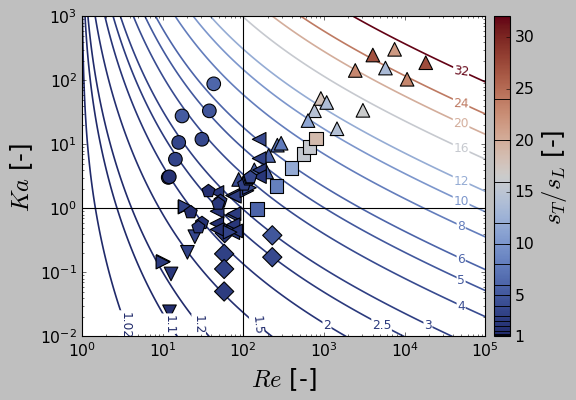

In [13]:
fig, b = panel()
Re = np.logspace(0, 5, 400); Ka = np.logspace(-2, 3, 400)
RR, KK = np.meshgrid(Re, Ka)
Z = sT(KK**0.5 * RR**0.25, RR)                                     # u'/s_L = Ka^1/2 Re^1/4
levels = [1.02, 1.1, 1.2, 1.5, 2, 2.5, 3, 4, 5, 6, 8, 10, 12, 16, 20, 24, 32]
vmin, vmax = 1, levels[-1]            # one linear scale for contours, symbols and colorbar
cs = b.contour(RR, KK, Z, levels=levels, linewidths=1.5, cmap=CMAP, vmin=vmin, vmax=vmax)
# one label per contour, where it first crosses the bottom, right or top edge
path = np.vstack([np.c_[np.logspace(0.3, 4.7, 300), np.full(300, 0.015)],
                  np.c_[np.full(300, 5e4), np.logspace(np.log10(0.015), np.log10(500), 300)],
                  np.c_[np.logspace(4.7, 0.3, 300), np.full(300, 500)]])
zp = sT(path[:, 1]**0.5 * path[:, 0]**0.25, path[:, 0])
manual = []
for v in levels:
    idx = np.nonzero(np.diff(np.sign(zp - v)))[0]
    if len(idx):
        manual.append(tuple(path[idx[0]]))
for t in b.clabel(cs, fmt='%g', fontsize=11, inline=False, manual=manual):
    t.set_bbox(dict(fc='white', ec='none', pad=0.5))
for s in sets:
    m = np.isfinite(s['ka']) & (s['ka'] > 0) & (s['re'] > 0)
    sc = b.scatter(s['re'][m], s['ka'][m], c=s['st'][m], marker=s['marker'], edgecolors='k', s=150,
                   cmap=CMAP, vmin=vmin, vmax=vmax, zorder=3)
b.axhline(1, color='k', linewidth=1)
b.axvline(100, color='k', linewidth=1)
b.set_xscale('log'); b.set_yscale('log')
b.set_xlim(1, 1e5); b.set_ylim(1e-2, 1e3)
b.set_xlabel(r'$\mathit{Re}$ [-]', fontsize=LABEL)
b.set_ylabel(r'$\mathit{Ka}$ [-]', fontsize=LABEL)
cb = fig.colorbar(sc, ax=b, pad=0.02, fraction=0.05, ticks=[1, 5, 10, 15, 20, 25, 30])
for v in levels:                      # mark the contour levels on the scale
    cb.ax.axhline(v, color='k', lw=0.8)
cb.set_label(r'$s_T/s_L$ [-]', fontsize=LABEL)
cb.ax.tick_params(labelsize=TICK)
save(fig, 'fig4b_landscape')

## Table 1 symbols (`figures/sym_<name>.pdf`)
Every file has the same canvas, so they scale identically with `\includegraphics[height=...]`.

In [14]:
w = 0.25  # inches; room for the largest marker (diamond) and its edge width
for s in sets:
    name = unicodedata.normalize('NFKD', s['label']).encode('ascii', 'ignore').decode()
    name = re.sub(r'[^a-z0-9]', '', name.lower())
    fig = plt.figure(figsize=(w, w))
    ax = fig.add_axes([0, 0, 1, 1])
    ax.plot([0.5], [0.5], ls='none', marker=s['marker'], mfc='none', mec=INK, mew=MEW, ms=MS)
    ax.set_xlim(0, 1); ax.set_ylim(0, 1); ax.axis('off')
    fig.savefig(os.path.join(OUT, f'sym_{name}.pdf'), transparent=True,
                bbox_inches=matplotlib.transforms.Bbox([[0, 0], [w, w]]))
    plt.close(fig)
print(sorted(f for f in os.listdir(OUT) if f.startswith('sym_')))

['sym_aachen2000.pdf', 'sym_damkohler1940.pdf', 'sym_michigan2005.pdf', 'sym_michigan2017.pdf', 'sym_ottawa1995.pdf', 'sym_tohoku1996.pdf', 'sym_toronto2013.pdf', 'sym_toronto2014.pdf']


## Agreement statistics and `predictions.csv`
These are the numbers quoted in §4 of the manuscript.

In [15]:
rows, allerr = [], []
for s in sets:
    p = sT(s['usl'], s['re'])
    e = np.log(s['st'] / p)
    allerr += list(e)
    for i in range(len(p)):
        rows.append(dict(dataset=s['label'], u_sL=s['usl'][i], l0_dL=s['ldl'][i], Re=s['re'][i],
                         Ka=s['ka'][i], F_Re=float(F(s['re'][i])), sT_sL_meas=s['st'][i],
                         sT_sL_pred=p[i], AT_A=s['at'][i]))
    print(f"{s['label']:18s} n={len(p):2d}  geometric-mean(meas/pred)={np.exp(e.mean()):.2f}  "
          f"rms log ratio={np.sqrt((e**2).mean()):.2f}")
allerr = np.array(allerr)
print(f"ALL                n={len(allerr)}  geometric-mean={np.exp(allerr.mean()):.2f}  "
      f"rms log ratio={np.sqrt((allerr**2).mean()):.2f}  "
      f"within factor 1.5: {np.mean(np.abs(allerr) < np.log(1.5)):.0%}")
pd.DataFrame(rows).to_csv(os.path.join(OUT, 'predictions.csv'), index=False)

Michigan (2017)    n=18  geometric-mean(meas/pred)=1.06  rms log ratio=0.21
Toronto (2013)     n= 8  geometric-mean(meas/pred)=1.06  rms log ratio=0.20
Tohoku (1996)      n= 4  geometric-mean(meas/pred)=1.83  rms log ratio=0.64
Aachen (2000)      n= 6  geometric-mean(meas/pred)=1.99  rms log ratio=0.69
Ottawa (1995)      n= 6  geometric-mean(meas/pred)=1.59  rms log ratio=0.49
Toronto (2014)     n=16  geometric-mean(meas/pred)=0.82  rms log ratio=0.33
Michigan (2005)    n= 7  geometric-mean(meas/pred)=1.37  rms log ratio=0.46
Damköhler (1940)   n=15  geometric-mean(meas/pred)=0.96  rms log ratio=0.24
ALL                n=80  geometric-mean=1.12  rms log ratio=0.38  within factor 1.5: 71%


# Supplementary material

## Distribution of the wrinkling exponent $\beta_w$
PDF of the local exponent returned by the dynamic procedure of Charlette *et al.* (2002*b*), digitised; mean and variance by trapezoidal integration.

In [16]:
bw = pd.read_csv(os.path.join(DATA, 'Charlette_2002b_beta_pdf.csv'), float_precision='round_trip').sort_values('beta_w')
beta_w = bw['beta_w'].to_numpy()
pdf_bw = np.maximum(bw['pdf'].to_numpy(), 0)                 # digitising can give small negatives
norm = trapezoid(pdf_bw, beta_w)
mean_bw = trapezoid(beta_w * pdf_bw, beta_w) / norm
var_bw = trapezoid((beta_w - mean_bw)**2 * pdf_bw, beta_w) / norm
std_bw = np.sqrt(var_bw)
print(f'mean = {mean_bw:.4f},  variance = {var_bw:.4f},  standard deviation = {std_bw:.4f}')

mean = 0.5875,  variance = 0.0109,  standard deviation = 0.1045


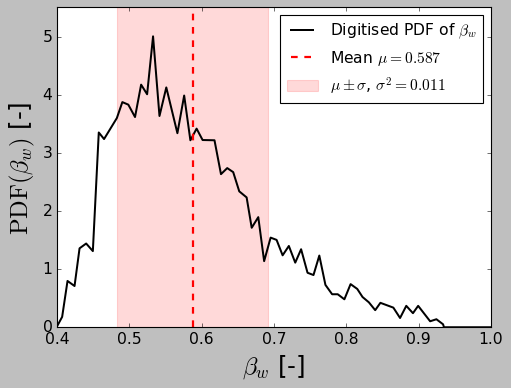

In [17]:
fig, ax = panel()
ax.plot(beta_w, pdf_bw, 'k-', lw=1.8, label=r'Digitised PDF of $\beta_w$')
ax.axvline(mean_bw, color='r', ls='--', lw=2, label=rf'Mean $\mu = {mean_bw:.3f}$')
ax.axvspan(mean_bw - std_bw, mean_bw + std_bw, color='r', alpha=0.15,
           label=rf'$\mu \pm \sigma$, $\sigma^2 = {var_bw:.3f}$')
ax.set_xlim(0.4, 1.0); ax.set_ylim(0, 1.1 * pdf_bw.max())
ax.set_xlabel(r'$\beta_w$ [-]', fontsize=LABEL)
ax.set_ylabel(r'$\mathrm{PDF}(\beta_w)$ [-]', fontsize=LABEL)
ax.legend(loc='upper right', fontsize=LEGEND)
save(fig, 'supp_beta_pdf')

## Scaling fan: $(s_T/s_L)/Ka$ against $Re$
Dashed lines are $100\,Re^{-n}$, each labelled with its slope $-n$.

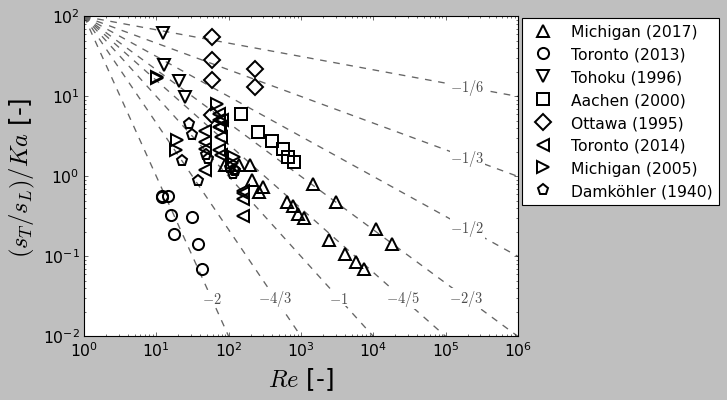

In [18]:
fig, ax = panel()
x = np.logspace(0, 6, 100)
fan = [(1 / 6, '1/6'), (1 / 3, '1/3'), (1 / 2, '1/2'), (2 / 3, '2/3'), (4 / 5, '4/5'), (1, '1'), (4 / 3, '4/3'),
       (2, '2')]
for n, lab in fan:
    ax.loglog(x, 100 * x**-n, color='0.4', ls='--', lw=1.2, zorder=0)
    xe = min(2e5, (100 / 0.03)**(1 / n))                           # near where the line leaves the axes
    ax.text(xe, 100 * xe**-n, rf'$-{lab}$', fontsize=13, color='0.3', ha='center', va='center',
            bbox=dict(fc='white', ec='none', pad=0.5), zorder=1)
for s in sets:
    m = np.isfinite(s['ka']) & (s['ka'] > 0) & (s['re'] > 0)
    mark(ax, s['re'][m], s['st'][m] / s['ka'][m], s, label=s['label'], zorder=2)
ax.set_xlim(1, 1e6); ax.set_ylim(0.01, 100)
ax.set_xlabel(r'$\mathit{Re}$ [-]', fontsize=LABEL)
ax.set_ylabel(r'$(s_T/s_L)/\mathit{Ka}$ [-]', fontsize=LABEL)
ax.legend(loc='upper left', bbox_to_anchor=(0.99, 1.02), fontsize=LEGEND, numpoints=1)
save(fig, 'supp_scaling_fan')